In [1]:
!pip install torch numpy
!pip install accelerate datasets transformers evaluate
import torch, transformers, datasets, accelerate, evaluate
import numpy as np
from transformers import AutoTokenizer, DataCollatorWithPadding, AutoModelForSequenceClassification, TrainingArguments, Trainer
from torch.utils.data import DataLoader
from datasets import get_dataset_split_names, load_dataset, get_dataset_config_names

In [3]:
# Load the toxicity dataset from Google Drive (columns: index, message, label).
from google.colab import drive
drive.mount('/content/drive')
# Use the RELABELLED file (14.4% toxic). The old cleaned_manual.csv has noisy labels the model memorises.
# Upload cleaned_manual_categorised_v3.csv to My Drive first, or change this path.
FILE_PATH = '/content/drive/MyDrive/cleaned_manual_v4.csv'

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from datasets import Dataset, Features, Value, ClassLabel

# Load and clean
df = pd.read_csv(FILE_PATH).rename(columns={"message": "text"})
df = df.drop(columns=[c for c in ("index", "Unnamed: 0") if c in df.columns])
df = df.dropna(subset=["text", "label"])
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(int)
df = df[df["text"].str.strip() != ""]

df["key"] = df["text"].str.lower().str.strip()
df = df[df["key"] != "#error!"]                         # drop spreadsheet junk

# One row per unique text; majority label settles conflicts like "wtf"
uniq = (df.groupby("key")
          .agg(text=("text", "first"), label=("label", "mean"))
          .reset_index())
uniq["label"] = uniq["label"].round().astype(int)

# 80 / 10 / 10 split by unique text, stratified on label
tr_keys, tmp_keys = train_test_split(uniq["key"], test_size=0.2,
                                     random_state=42, stratify=uniq["label"])
tmp = uniq[uniq["key"].isin(tmp_keys)]
val_keys, te_keys = train_test_split(tmp["key"], test_size=0.5,
                                     random_state=42, stratify=tmp["label"])

train_df = df[df["key"].isin(tr_keys)][["text", "label"]]    # keeps duplicates
val_df   = uniq[uniq["key"].isin(val_keys)][["text", "label"]]
test_df  = uniq[uniq["key"].isin(te_keys)][["text", "label"]]

feats = Features({"text": Value("string"),
                  "label": ClassLabel(names=["not toxic", "toxic"])})
to_ds = lambda d: Dataset.from_pandas(d.reset_index(drop=True), features=feats, preserve_index=False)

train_ds = to_ds(train_df).shuffle(seed=42)
val_ds   = to_ds(val_df)
test_ds  = to_ds(test_df)

print(len(train_ds), len(val_ds), len(test_ds))
print("toxic rate  train/val/test:",
      round(np.mean(train_ds["label"]), 3),
      round(np.mean(val_ds["label"]), 3),
      round(np.mean(test_ds["label"]), 3))

Mounted at /content/drive
19499 2384 2384
toxic rate  train/val/test: 0.144 0.145 0.145


In [4]:
from transformers import set_seed
set_seed(42)   # same initial classifier weights and data order every run

MODEL_ID = "google-bert/bert-base-uncased"   # 110M parameters, lower-cases text
DROPOUT  = 0.1   # raise to 0.2 if it still overfits after early stopping

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
# Re-run this cell before every new training run: training again on the same `model` continues from the old weights
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, num_labels=2, torch_dtype="auto",
    id2label={0: "not offensive", 1: "offensive"}, label2id={"not offensive": 0, "offensive": 1},
    hidden_dropout_prob=DROPOUT, attention_probs_dropout_prob=DROPOUT,
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [5]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=32)

train_ds = train_ds.map(tokenize_function, batched=True)
val_ds   = val_ds.map(tokenize_function, batched=True)
test_ds  = test_ds.map(tokenize_function, batched=True)

Map:   0%|          | 0/19499 [00:00<?, ? examples/s]

Map:   0%|          | 0/2384 [00:00<?, ? examples/s]

Map:   0%|          | 0/2384 [00:00<?, ? examples/s]

In [6]:
training_args = TrainingArguments(output_dir="bert_trainer")

In [7]:
accuracy_metric  = evaluate.load("accuracy")
f1_metric        = evaluate.load("f1")         # F1 on the "toxic" class (label 1); accuracy alone is misleading when toxic messages are rare
precision_metric = evaluate.load("precision")
recall_metric    = evaluate.load("recall")

In [8]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    out = {}
    out.update(accuracy_metric.compute(predictions=predictions, references=labels))
    out.update(precision_metric.compute(predictions=predictions, references=labels, zero_division=0))  # toxic class
    out.update(recall_metric.compute(predictions=predictions, references=labels, zero_division=0))     # toxic class
    out.update(f1_metric.compute(predictions=predictions, references=labels))                          # toxic class
    return out

In [9]:
from transformers import EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir="bert_trainer",
    report_to="none",
    num_train_epochs=20,             # was 8: validation loss bottomed out at epoch 1-2 and F1 plateaued by epoch 2-5
    learning_rate=2e-5,             # too big a learning rate makes training diverge; try 1e-5 if it still overfits
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    logging_strategy="epoch",
    eval_strategy="epoch",          # score the validation set after every epoch
    save_strategy="epoch",          # save a checkpoint every epoch (must match eval_strategy)
    save_total_limit=2,             # keep only the best and the latest checkpoint on disk
    load_best_model_at_end=True,    # at the end, reload the BEST epoch instead of keeping the last (overfit) one
    metric_for_best_model="f1",     # "best" = highest toxic-class F1 on the validation set
    greater_is_better=True,
    seed=42,
)

In [10]:
import torch.nn as nn

pos = sum(train_ds["label"])
neg = len(train_ds) - pos
# Square root of the class ratio: still favours the rarer toxic class, but less aggressively than neg/pos (~4.9x),
# which made the model memorise individual (sometimes mislabelled) toxic examples.
class_weights = torch.tensor([1.0, (neg / pos) ** 0.5], dtype=torch.float)
print("class weights:", class_weights)

LABEL_SMOOTHING = 0.1   # stops the model pushing probabilities to exactly 0 or 1 (the cause of the rising validation loss)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device),
                                      label_smoothing=LABEL_SMOOTHING)
        loss = loss_fn(outputs.logits.float(), labels)
        return (loss, outputs) if return_outputs else loss

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],   # stop if validation F1 fails to improve for 2 epochs
)

class weights: tensor([1.0000, 2.4365])


In [11]:
print("model outputs:", model.config.num_labels)
print("train labels:", set(train_ds["label"]))
print("val labels:  ", set(val_ds["label"]))
print("test labels: ", set(test_ds["label"]))

model outputs: 2
train labels: {0, 1}
val labels:   {0, 1}
test labels:  {0, 1}


In [12]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.441657,0.397722,0.957215,0.827957,0.890173,0.857939
2,0.376037,0.395901,0.959732,0.859195,0.864162,0.861671
3,0.350149,0.403459,0.958893,0.826316,0.907514,0.865014
4,0.333092,0.413226,0.960990,0.868805,0.861272,0.865022
5,0.323941,0.408118,0.961409,0.852778,0.887283,0.869688
6,0.320489,0.408605,0.962668,0.868195,0.875723,0.871942
7,0.315118,0.407044,0.961409,0.841398,0.904624,0.871866
8,0.312113,0.413420,0.960570,0.855932,0.875723,0.865714


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=4880, training_loss=0.3465746801407611, metrics={'train_runtime': 759.3678, 'train_samples_per_second': 205.424, 'train_steps_per_second': 6.426, 'total_flos': 1600917202445220.0, 'train_loss': 0.3465746801407611, 'epoch': 8.0})

### Evaluate once on the held-out TEST set


In [13]:
# Final, one-time evaluation on the HELD-OUT TEST set (never used for training or tuning).
test_metrics = trainer.evaluate(eval_dataset=test_ds)
print("Held-out TEST metrics:", test_metrics)
print({k: round(v, 4) for k, v in test_metrics.items() if k.startswith('eval_')})

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.312113,0.410197,8,0.960151,0.853521,0.875723,0.864479


Held-out TEST metrics: {'eval_loss': 0.4101966619491577, 'eval_accuracy': 0.9601510067114094, 'eval_precision': 0.8535211267605634, 'eval_recall': 0.8757225433526011, 'eval_f1': 0.8644793152639088}
{'eval_loss': 0.4102, 'eval_accuracy': 0.9602, 'eval_precision': 0.8535, 'eval_recall': 0.8757, 'eval_f1': 0.8645}


### Qualitative inspection

In [14]:
# Qualitative inspection: look at TEST examples the model got WRONG.
label_names = ["not toxic", "toxic"]

test_predictions = trainer.predict(test_ds)
pred_ids = np.argmax(test_predictions.predictions, axis=-1)
true_ids = test_predictions.label_ids

# False negatives: truly toxic, predicted not toxic
fn = np.where((true_ids == 1) & (pred_ids == 0))[0]
# False positives: truly not toxic, predicted toxic
fp = np.where((true_ids == 0) & (pred_ids == 1))[0]
print(f"False negatives (missed toxic): {len(fn)}   False positives (over-flagged): {len(fp)}\n")

def show(indices, title, n=10):
    print(f"=== {title} ===")
    for i in indices[:n]:
        print(f"PRED: {label_names[pred_ids[i]]:<9} TRUE: {label_names[true_ids[i]]:<9} TEXT: {test_ds[int(i)]['text'][:200]}")
    print()

show(fn, "Missed toxic messages")
show(fp, "Non-toxic messages flagged as toxic")

False negatives (missed toxic): 43   False positives (over-flagged): 52

=== Missed toxic messages ===
PRED: not toxic TRUE: toxic     TEXT: *** off team
PRED: not toxic TRUE: toxic     TEXT: *** udes
PRED: not toxic TRUE: toxic     TEXT: AKURVA ??LETBE
PRED: not toxic TRUE: toxic     TEXT: barindead heavys
PRED: not toxic TRUE: toxic     TEXT: Black prince its almost like our heavy tanks did fucking nothing
PRED: not toxic TRUE: toxic     TEXT: brainless
PRED: not toxic TRUE: toxic     TEXT: bro shut the hell up
PRED: not toxic TRUE: toxic     TEXT: damn tomato
PRED: not toxic TRUE: toxic     TEXT: dolboebi
PRED: not toxic TRUE: toxic     TEXT: dumd ass elc

=== Non-toxic messages flagged as toxic ===
PRED: toxic     TRUE: not toxic TEXT: *** useless
PRED: toxic     TRUE: not toxic TEXT: *fap*fap*fap*
PRED: toxic     TRUE: not toxic TEXT: and just for you will know firstly I wasnt talking an ??out you achi... but know I know both of you are morons
PRED: toxic     TRUE: not toxic TEXT:

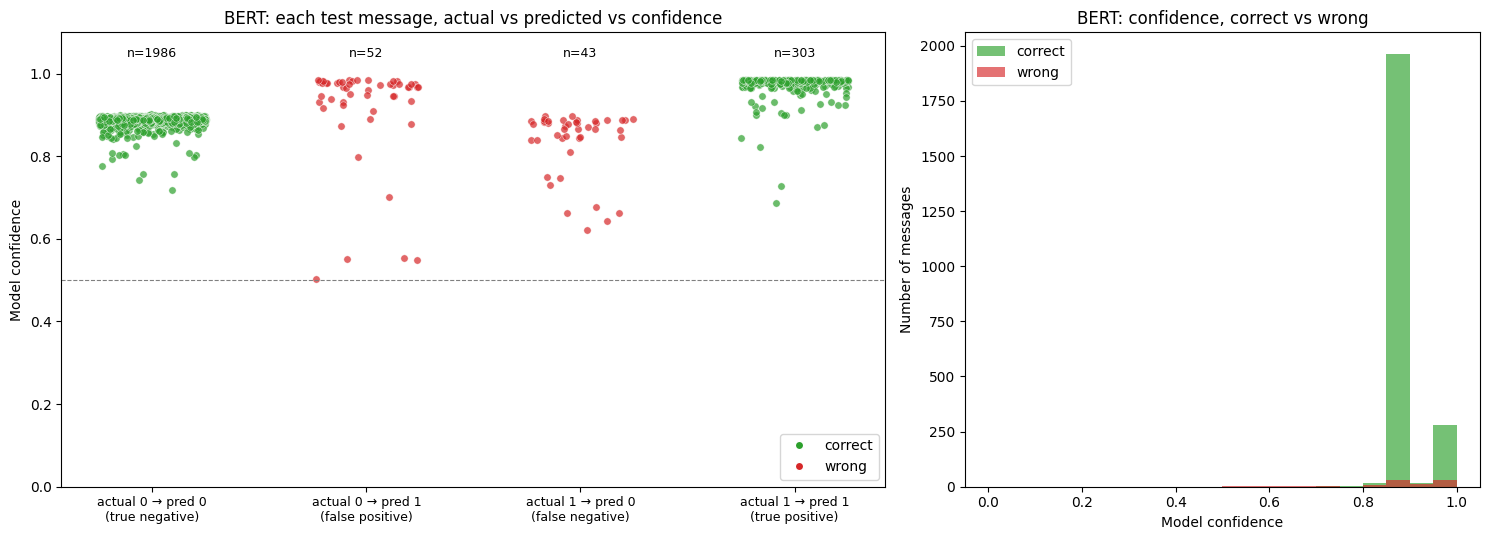

Mean confidence, correct predictions: 0.898
Mean confidence, wrong predictions:   0.882

Accuracy: 0.96

Classification report:
                   precision    recall  f1-score   support

not offensive (0)      0.979     0.974     0.977      2038
    offensive (1)      0.854     0.876     0.864       346

         accuracy                          0.960      2384
        macro avg      0.916     0.925     0.921      2384
     weighted avg      0.961     0.960     0.960      2384

Confusion matrix (rows = actual, columns = predicted):
          pred 0  pred 1
actual 0    1986      52
actual 1      43     303


In [15]:
# Confidence plots + classification report (same layout as the Laya results)
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

MODEL_NAME = "BERT"   # <-- change to "BERT" in the BERT notebook (used in the plot titles)

pred_out = trainer.predict(test_ds)                       # uses the best epoch the trainer reloaded
probs = torch.softmax(torch.tensor(pred_out.predictions, dtype=torch.float), dim=-1).numpy()
plot_df = pd.DataFrame({
    "text": test_ds["text"],
    "actual": pred_out.label_ids.astype(int).astype(str),
    "pred": probs.argmax(1).astype(str),
    "confidence": probs.max(1),                           # probability of the predicted label, like Laya's answer_confidence
})
plot_df["correct"] = plot_df["actual"] == plot_df["pred"]

groups = [("0", "0"), ("0", "1"), ("1", "0"), ("1", "1")]
names = {("0", "0"): "actual 0 → pred 0\n(true negative)", ("0", "1"): "actual 0 → pred 1\n(false positive)",
         ("1", "0"): "actual 1 → pred 0\n(false negative)", ("1", "1"): "actual 1 → pred 1\n(true positive)"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

ax = axes[0]
rng = np.random.default_rng(0)
for i, (a, p) in enumerate(groups):
    sub = plot_df[(plot_df["actual"] == a) & (plot_df["pred"] == p)]
    x = i + rng.uniform(-0.25, 0.25, len(sub))            # jitter so dots don't overlap
    ax.scatter(x, sub["confidence"], s=28, alpha=0.7, color="tab:green" if a == p else "tab:red",
               edgecolor="white", linewidth=0.4)
    ax.text(i, 1.04, f"n={len(sub)}", ha="center", fontsize=9)
ax.set_xticks(range(len(groups))); ax.set_xticklabels([names[g] for g in groups], fontsize=9)
ax.set_ylabel("Model confidence"); ax.set_ylim(0, 1.1)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
ax.set_title(f"{MODEL_NAME}: each test message, actual vs predicted vs confidence")
ax.legend(handles=[plt.Line2D([], [], marker="o", color="w", markerfacecolor="tab:green", label="correct"),
                   plt.Line2D([], [], marker="o", color="w", markerfacecolor="tab:red", label="wrong")], loc="lower right")

ax = axes[1]
bins = np.linspace(0, 1, 21)
ax.hist(plot_df.loc[plot_df["correct"], "confidence"], bins=bins, alpha=0.65, color="tab:green", label="correct")
ax.hist(plot_df.loc[~plot_df["correct"], "confidence"], bins=bins, alpha=0.65, color="tab:red", label="wrong")
ax.set_xlabel("Model confidence"); ax.set_ylabel("Number of messages")
ax.set_title(f"{MODEL_NAME}: confidence, correct vs wrong"); ax.legend()
plt.tight_layout(); plt.show()

print("Mean confidence, correct predictions:", round(plot_df.loc[plot_df["correct"], "confidence"].mean(), 3))
print("Mean confidence, wrong predictions:  ", round(plot_df.loc[~plot_df["correct"], "confidence"].mean(), 3))
print("\nAccuracy:", round(accuracy_score(plot_df["actual"], plot_df["pred"]), 3))
print("\nClassification report:")
print(classification_report(plot_df["actual"], plot_df["pred"], labels=["0", "1"],
                            target_names=["not offensive (0)", "offensive (1)"], zero_division=0, digits=3))
print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(confusion_matrix(plot_df["actual"], plot_df["pred"], labels=["0", "1"]),
                   index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))